In [3]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.metrics import silhouette_score

from sklearn.cluster import  KMeans

df  = pd.read_csv(Path("../3-clusterização/dados_clusterizacao") / "adult25_clusterizacao_onehot_2025.csv", low_memory=False)

df_completos = pd.read_csv(Path("../1-limpeza/dados/dados_limpos") / "adult25_limpo.csv", low_memory=False)

print(f"\nBase selecionada importada com sucesso!")
print(f"Dimensões finais: {df.shape[0]:,} participantes e {df.shape[1]} atributos.")

inercias, silhouettes = [], []
k = 2

km = KMeans(n_clusters=k,
        init='k-means++',
        n_init=10,
        max_iter=300,
        tol=1e-4,
        random_state=42
    )

labels = km.fit_predict(df)
inercias.append(km.inertia_)

labels = pd.DataFrame(labels, columns=['cluster'])

print(df.head())



Base selecionada importada com sucesso!
Dimensões finais: 24,215 participantes e 389 atributos.
   RAZAO_RENDA_POBREZA  IDADE__-1  IDADE__18  IDADE__19  IDADE__20  IDADE__21  \
0                 1.58          0          0          0          0          0   
1                 4.32          0          0          0          0          0   
2                 0.18          0          0          1          0          0   
3                 6.32          0          0          0          0          0   
4                 4.90          0          0          0          0          0   

   IDADE__22  IDADE__23  IDADE__24  IDADE__25  ...  \
0          0          0          0          0  ...   
1          0          0          0          0  ...   
2          0          0          0          0  ...   
3          0          0          0          0  ...   
4          0          0          0          0  ...   

   TIPO_DIFICULDADE_COGNITIVA__-1  TIPO_DIFICULDADE_COGNITIVA__1  \
0                      

In [4]:
assert len(labels) == len(df_completos), (
    "A quantidade de labels deve corresponder à quantidade de registros em df_completos."
)

labels_com_frequencia = pd.concat(
    [
        labels.reset_index(drop=True),
        df_completos[["SEVERIDADE_DEPRESSAO_PHQ"]].reset_index(drop=True),
    ],
    axis=1,
)

labels_com_frequencia.value_counts()

cluster  SEVERIDADE_DEPRESSAO_PHQ
0         1                          12675
1         1                           5929
0         2                           2645
          3                            928
1         2                            707
0         4                            530
         -1                            444
1         3                            155
         -1                            152
          4                             50
Name: count, dtype: int64

In [5]:
print(labels.value_counts())

cluster
0          17222
1           6993
Name: count, dtype: int64


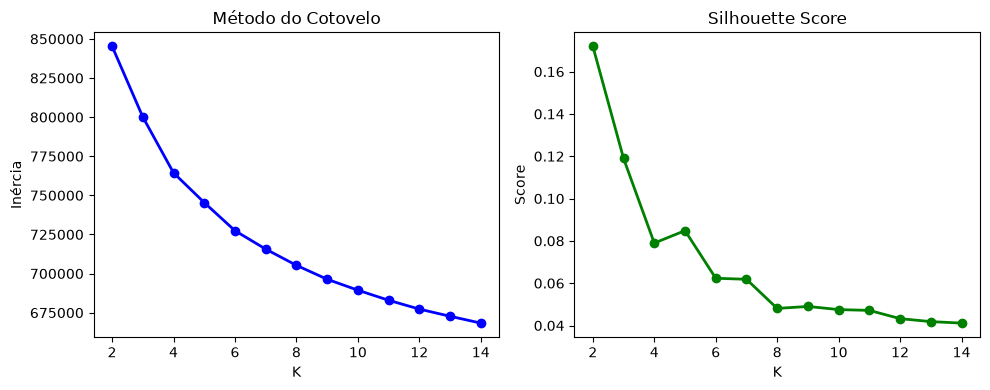

In [18]:
inercias, silhouettes = [], []
ks = range(2,15)
for k in ks:
    km = KMeans(n_clusters=k,
            init='k-means++',
            n_init=10,
            max_iter=300,
            tol=1e-4,
            random_state=42
        )
    labels = km.fit_predict(df)
    inercias.append(km.inertia_)
    silhouettes.append(silhouette_score(df, labels))



# Plotar diagnóstico
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
ax1.plot(ks, inercias, 'bo-', linewidth=2)
ax1.set_title('Método do Cotovelo'); ax1.set_xlabel('K'); ax1.set_ylabel('Inércia')
ax2.plot(ks, silhouettes, 'go-', linewidth=2)
ax2.set_title('Silhouette Score'); ax2.set_xlabel('K'); ax2.set_ylabel('Score')
plt.tight_layout(); plt.show()
